# Submission 2: Pretrained CNNs With and Without Fine-Tuning
## Waste Image Classification Using Transfer Learning and an Attention-Enhanced Custom CNN: A Comparative Study

**Course:** CSE366 Artificial Intelligence, East West University  
**Instructor:** Dr. Tania Sultana  
**Group:** 08 (Sadia Afrin, Md. Nahid Howladar, Fahmida Kabir, Tanvir Ahmed)

**Goal.** Compare three ImageNet-pretrained CNNs (MobileNetV2, ResNet50, EfficientNetB0) on TrashNet in two modes, giving **six runs**:

| Mode | What is trained |
|---|---|
| **Frozen (feature extraction)** | The pretrained backbone is frozen; only the new classification head is trained. |
| **Fine-tuned** | The last stage(s) of the backbone are unfrozen and trained together with the new head, using a smaller learning rate for the backbone. |

For every run the notebook reports: train vs validation accuracy curve, train vs validation loss curve, classification report (precision, recall, F1 per class), confusion matrix on the test set, and training and testing time. All six runs use **the same split manifest, preprocessing, optimizer family and epoch budget**, so differences come from the model and the mode only.

## 0. Setup

The notebook was run on Kaggle with a Tesla T4 GPU, as shown in the device line below.

In [1]:
# Packages that are usually missing on a fresh machine (PyTorch/torchvision are preinstalled on Kaggle and Colab).
%pip install -q scikit-learn seaborn pandas matplotlib pillow requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, io, json, time, copy, random, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from PIL import Image
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

import torch, torch.nn as nn
import torchvision
from torchvision import models, transforms as T

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

IN_KAGGLE = os.path.exists("/kaggle/working")
IN_COLAB = "google.colab" in sys.modules
WORK = Path("/kaggle/working") if IN_KAGGLE else Path(".")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Environment:", "Kaggle" if IN_KAGGLE else "Colab" if IN_COLAB else "local")
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "no GPU found")

PyTorch: 2.11.0+cu128 | torchvision: 0.26.0+cu128
Environment: Kaggle
Device: cuda | Tesla T4


### 0.1 Experiment configuration

All settings are in the cell below. The roadmap asks for 30-50 epochs per mode, so every run uses `EPOCHS = 30`. Early stopping is not used, so every run trains for the full 30 epochs; the checkpoint with the lowest validation loss is kept and used for the test set.

In [3]:
SEED = 42
EPOCHS = 30                 # roadmap: 30-50 epochs for each mode
BATCH_SIZE = 32
IMG_SIZE = 224
LR_HEAD = 1e-3              # new classification head (both modes)
LR_BACKBONE = 1e-4          # unfrozen backbone layers (fine-tuned mode only)
WEIGHT_DECAY = 1e-4
DROPOUT = 0.3
NUM_WORKERS = 0 if os.name == "nt" else 2
USE_AMP = DEVICE.type == "cuda"      # mixed precision speeds up GPU training
FORCE_RERUN = True         # True = ignore saved results and retrain every run
SMOKE_TEST = False          # True = tiny quick check of the code (1 epoch, few images, no pretrained weights)

CLASSES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}

RESULTS = WORK / "results_sub2"
FIGS = RESULTS / "figures"
for d in (RESULTS, FIGS):
    d.mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(SEED)

if SMOKE_TEST:
    EPOCHS = 1
    print("SMOKE TEST MODE: tiny subset, 1 epoch, random weights. Results are meaningless.")

## 1. Data

### 1.1 Dataset and the fixed split from Submission 1

The images come from the original TrashNet repository (`dataset-resized.zip`). The **same `split_manifest.csv` from Submission 1** (stratified 70/15/15, seed 42) is used, so training, validation and test images are identical for all six runs. The test set is used only once per run, after training.

In [4]:
DATA_URL = "https://raw.githubusercontent.com/garythung/trashnet/master/data/dataset-resized.zip"
MANIFEST_URL = "https://raw.githubusercontent.com/NahidTheCracker/waste-classification-transfer-learning-attention-cnn/main/split_manifest.csv"
DATA_DIR = WORK / "trashnet_data"

def find_root(base):
    for p, dirs, _ in os.walk(base):
        if "__MACOSX" in p:
            continue
        if all(c in dirs for c in CLASSES):
            return Path(p)
    return None

DATA_ROOT = find_root(DATA_DIR) if DATA_DIR.exists() else None
if DATA_ROOT is None:
    print("Downloading TrashNet ...")
    r = requests.get(DATA_URL, timeout=300); r.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        z.extractall(DATA_DIR)
    DATA_ROOT = find_root(DATA_DIR)
assert DATA_ROOT is not None, "Class folders not found; check the internet setting or unzip the dataset into ./trashnet_data"

# Load the manifest: local copy first, otherwise download it from the project repository.
manifest = None
for cand in [WORK / "split_manifest.csv", WORK / "splits" / "split_manifest.csv", Path("split_manifest.csv")]:
    if cand.exists():
        manifest = pd.read_csv(cand); break
if manifest is None:
    manifest = pd.read_csv(MANIFEST_URL)
manifest["label_idx"] = manifest["label"].map(CLASS_TO_IDX)

if SMOKE_TEST:
    manifest = manifest.groupby(["split", "label"]).head(6).reset_index(drop=True)

print("Dataset root:", DATA_ROOT)
print(pd.crosstab(manifest["label"], manifest["split"])[["train", "val", "test"]].reindex(CLASSES))
print("Totals:", manifest["split"].value_counts().to_dict())

Dataset root: /kaggle/working/trashnet_data/dataset-resized
split      train  val  test
label                      
cardboard    282   61    60
glass        350   75    76
metal        287   62    61
paper        416   89    89
plastic      337   73    72
trash         96   20    21
Totals: {'train': 1768, 'val': 380, 'test': 379}


### 1.2 Preprocessing and augmentation

- All images are resized to 224 x 224 RGB and normalized with the ImageNet mean and standard deviation. The three torchvision models used here were pretrained with this same normalization, so one pipeline is correct for all of them.
- **Augmentation is applied to the training set only:** random resized crop (scale 0.75-1.0), horizontal flip, rotation up to 20 degrees and mild brightness/contrast changes. Strong colour changes are avoided because colour and texture help identify materials (as noted in Submission 1).
- **Class imbalance** (trash has 137 images and paper 594) is handled with class weights in the loss, computed from the **training split only**.
- Images are decoded and resized once and kept in memory, so epochs run fast.

In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.75, 1.0), ratio=(0.9, 1.1)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(20),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(), T.Normalize(MEAN, STD)])
eval_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

class TrashDataset(torch.utils.data.Dataset):
    def __init__(self, df, transform):
        self.transform = transform
        self.labels = df["label_idx"].tolist()
        self.images = []
        for p in df["path"]:
            with Image.open(DATA_ROOT / p) as im:
                self.images.append(im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
    def __len__(self): return len(self.labels)
    def __getitem__(self, i): return self.transform(self.images[i]), self.labels[i]

splits = {s: manifest[manifest["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
datasets = {"train": TrashDataset(splits["train"], train_tf),
            "val": TrashDataset(splits["val"], eval_tf),
            "test": TrashDataset(splits["test"], eval_tf)}

def make_loader(split, shuffle=False):
    return torch.utils.data.DataLoader(datasets[split], batch_size=BATCH_SIZE, shuffle=shuffle,
                                       num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
loaders = {"train": make_loader("train", True), "val": make_loader("val"), "test": make_loader("test")}

# class weights from the training split only
train_counts = np.bincount(splits["train"]["label_idx"], minlength=len(CLASSES))
CLASS_WEIGHTS = torch.tensor(train_counts.sum() / (len(CLASSES) * train_counts), dtype=torch.float32)
print("Train counts:", dict(zip(CLASSES, train_counts.tolist())))
print("Class weights:", dict(zip(CLASSES, CLASS_WEIGHTS.numpy().round(2).tolist())))

Train counts: {'cardboard': 282, 'glass': 350, 'metal': 287, 'paper': 416, 'plastic': 337, 'trash': 96}
Class weights: {'cardboard': 1.0399999618530273, 'glass': 0.8399999737739563, 'metal': 1.0299999713897705, 'paper': 0.7099999785423279, 'plastic': 0.8700000047683716, 'trash': 3.069999933242798}


## 2. Models and training setup

### 2.1 The three architectures and the two modes

Each model is loaded with ImageNet weights, and its final layer is replaced by a dropout layer and a new linear layer with 6 outputs.

| Model | Frozen mode trains | Fine-tuned mode additionally unfreezes |
|---|---|---|
| MobileNetV2 | new classifier | last four inverted-residual blocks (`features[14:]`) |
| ResNet50 | new `fc` layer | last residual stage (`layer4`) |
| EfficientNetB0 | new classifier | last stages (`features[6:]`) |

In fine-tuned mode the new head uses `LR_HEAD` and the unfrozen backbone layers use the smaller `LR_BACKBONE`, so pretrained features are adjusted gently instead of being overwritten. Batch-normalization layers inside frozen parts are kept in evaluation mode so their ImageNet statistics are not disturbed.

### 2.2 Training and overfitting control

Every run uses AdamW with weight decay, a cosine learning-rate schedule, class-weighted cross-entropy, dropout in the head, and data augmentation. The best checkpoint (lowest validation loss) is restored before testing, which guards against selecting an overfitted final epoch. The gap between training and validation accuracy is checked automatically after each run.

In [6]:
def build_model(arch, mode):
    pretrained = not SMOKE_TEST
    n = len(CLASSES)
    if arch == "mobilenet_v2":
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(m.last_channel, n))
        head, unfreeze = list(m.classifier.parameters()), list(m.features[14:].parameters())
    elif arch == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None)
        m.fc = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(m.fc.in_features, n))
        head, unfreeze = list(m.fc.parameters()), list(m.layer4.parameters())
    elif arch == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(m.classifier[1].in_features, n))
        head, unfreeze = list(m.classifier.parameters()), list(m.features[6:].parameters())
    else:
        raise ValueError(arch)

    for p in m.parameters():
        p.requires_grad = False
    for p in head:
        p.requires_grad = True
    groups = [{"params": head, "lr": LR_HEAD}]
    if mode == "finetuned":
        for p in unfreeze:
            p.requires_grad = True
        groups.append({"params": unfreeze, "lr": LR_BACKBONE})
    return m.to(DEVICE), groups

def set_train_mode(model):
    model.train()
    for mod in model.modules():            # keep frozen BatchNorm layers in eval mode
        if isinstance(mod, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in mod.parameters()):
            mod.eval()

def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

@torch.no_grad()
def predict(model, loader, criterion=None):
    model.eval()
    losses, ys, ps = 0.0, [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            out = model(x)
            if criterion is not None:
                losses += criterion(out, y).item() * len(y)
        ys.append(y.cpu()); ps.append(out.argmax(1).cpu())
    y_true, y_pred = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return (losses / len(y_true) if criterion is not None else None), y_true, y_pred

def train_model(arch, mode, out_dir):
    seed_everything(SEED)
    model, groups = build_model(arch, mode)
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for g in groups for p in g["params"])
    criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE))
    optimizer = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history, best_loss, best_state, best_epoch, train_time = [], float("inf"), None, 0, 0.0
    for epoch in range(1, EPOCHS + 1):
        sync(); t0 = time.time()
        set_train_mode(model)
        run_loss, correct, seen = 0.0, 0, 0
        for x, y in loaders["train"]:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                out = model(x); loss = criterion(out, y)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            run_loss += loss.item() * len(y); correct += (out.argmax(1) == y).sum().item(); seen += len(y)
        scheduler.step()
        val_loss, yv, pv = predict(model, loaders["val"], criterion)
        sync(); dt = time.time() - t0; train_time += dt
        rec = dict(epoch=epoch, train_loss=run_loss / seen, train_acc=correct / seen,
                   val_loss=val_loss, val_acc=accuracy_score(yv, pv), epoch_time_s=dt)
        history.append(rec)
        if val_loss < best_loss:
            best_loss, best_epoch, best_state = val_loss, epoch, copy.deepcopy(model.state_dict())
        print(f"[{arch} | {mode}] epoch {epoch:02d}/{EPOCHS}  train loss {rec['train_loss']:.3f} acc {rec['train_acc']:.3f}"
              f"  |  val loss {rec['val_loss']:.3f} acc {rec['val_acc']:.3f}  ({dt:.1f}s)")

    model.load_state_dict(best_state)                       # restore the best checkpoint
    torch.save(best_state, out_dir / "best.pt")
    sync(); t0 = time.time()
    _, y_true, y_pred = predict(model, loaders["test"])     # test set used once, after training
    sync(); test_time = time.time() - t0
    return history, y_true, y_pred, dict(train_time_s=train_time, test_time_s=test_time, best_epoch=best_epoch,
                                         total_params=total, trainable_params=trainable)

### 2.3 Running one experiment and showing its results

`run_experiment` trains one model in one mode, saves everything under `results_sub2/<model>_<mode>/`, and displays the accuracy curve, loss curve, classification report, test confusion matrix, and training and testing time.

In [7]:
PRETTY = {"mobilenet_v2": "MobileNetV2", "resnet50": "ResNet50", "efficientnet_b0": "EfficientNetB0"}
MODE_NAME = {"frozen": "Frozen", "finetuned": "Fine-tuned"}

def diagnose(hist, best_epoch):
    last, best = hist.iloc[-1], hist.loc[hist["epoch"] == best_epoch].iloc[0]
    gap = (last["train_acc"] - last["val_acc"]) * 100
    rise = last["val_loss"] - hist["val_loss"].min()
    msg = []
    msg.append(f"Final-epoch train acc {last['train_acc']*100:.1f}% vs validation acc {last['val_acc']*100:.1f}% (gap {gap:+.1f} points).")
    msg.append(f"Best validation loss {hist['val_loss'].min():.3f} at epoch {best_epoch}; final validation loss is {rise:+.3f} above it.")
    if gap > 8 or rise > 0.15:
        msg.append("Diagnosis: signs of OVERFITTING (large train-validation gap or rising validation loss). The best-validation-loss checkpoint is used for testing.")
    elif last["train_acc"] < 0.80 and last["val_acc"] < 0.80:
        msg.append("Diagnosis: signs of UNDERFITTING (both accuracies are still low).")
    else:
        msg.append("Diagnosis: no strong sign of over- or underfitting.")
    print("\n".join(msg))

def show_results(title, hist, y_true, y_pred, met):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(hist["epoch"], hist["train_acc"], label="Train"); ax[0].plot(hist["epoch"], hist["val_acc"], label="Validation")
    ax[0].axvline(met["best_epoch"], ls="--", c="gray", lw=1, label=f"Best epoch ({met['best_epoch']})")
    ax[0].set_title(f"{title}: accuracy"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].legend()
    ax[1].plot(hist["epoch"], hist["train_loss"], label="Train"); ax[1].plot(hist["epoch"], hist["val_loss"], label="Validation")
    ax[1].axvline(met["best_epoch"], ls="--", c="gray", lw=1)
    ax[1].set_title(f"{title}: loss"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].legend()
    plt.tight_layout(); plt.savefig(FIGS / f"{met['run']}_curves.png", dpi=200); plt.show()

    diagnose(hist, met["best_epoch"])
    print("\nClassification report (test set):")
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0], cbar=False)
    ax[0].set_title(f"{title}: confusion matrix (counts)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")
    cmn = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1], cbar=False)
    ax[1].set_title(f"{title}: confusion matrix (row-normalized)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("True")
    plt.tight_layout(); plt.savefig(FIGS / f"{met['run']}_confusion.png", dpi=200); plt.show()

    print(f"Test accuracy {met['test_acc']*100:.2f}% | macro-F1 {met['macro_f1']:.3f}")
    print(f"Training time: {met['train_time_s']/60:.1f} min ({met['train_time_s']:.0f} s for {len(hist)} epochs) | "
          f"Testing time: {met['test_time_s']:.2f} s for {len(y_true)} images ({met['test_time_s']/len(y_true)*1000:.1f} ms/image)")
    print(f"Parameters: {met['trainable_params']:,} trainable of {met['total_params']:,}")

def run_experiment(arch, mode):
    run = f"{arch}_{mode}"
    out = RESULTS / run; out.mkdir(parents=True, exist_ok=True)
    saved = all((out / f).exists() for f in ["metrics.json", "history.csv", "preds.npz"])
    if saved and not FORCE_RERUN:
        print(f"Loading saved results for {run} (set FORCE_RERUN = True to retrain).")
        met = json.load(open(out / "metrics.json")); hist = pd.read_csv(out / "history.csv")
        p = np.load(out / "preds.npz"); y_true, y_pred = p["y_true"], p["y_pred"]
    else:
        history, y_true, y_pred, info = train_model(arch, mode, out)
        hist = pd.DataFrame(history)
        pr, rc, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
        met = dict(run=run, model=PRETTY[arch], mode=MODE_NAME[mode], epochs=EPOCHS,
                   test_acc=float(accuracy_score(y_true, y_pred)), macro_precision=float(pr), macro_recall=float(rc),
                   macro_f1=float(f1), weighted_f1=float(precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)[2]),
                   final_train_acc=float(hist.iloc[-1]["train_acc"]), final_val_acc=float(hist.iloc[-1]["val_acc"]),
                   best_val_loss=float(hist["val_loss"].min()), **info)
        hist.to_csv(out / "history.csv", index=False)
        np.savez(out / "preds.npz", y_true=y_true, y_pred=y_pred)
        json.dump(met, open(out / "metrics.json", "w"), indent=2)
    show_results(f"{PRETTY[arch]} ({MODE_NAME[mode]})", hist, y_true, y_pred, met)
    return met

ALL_METRICS = {}

## 3. Experiments

### 3.1 MobileNetV2: frozen

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 122MB/s]


[mobilenet_v2 | frozen] epoch 01/30  train loss 1.320 acc 0.516  |  val loss 0.886 acc 0.684  (14.5s)
[mobilenet_v2 | frozen] epoch 02/30  train loss 0.872 acc 0.707  |  val loss 0.805 acc 0.724  (4.3s)
[mobilenet_v2 | frozen] epoch 03/30  train loss 0.769 acc 0.740  |  val loss 0.719 acc 0.726  (4.3s)
[mobilenet_v2 | frozen] epoch 04/30  train loss 0.690 acc 0.764  |  val loss 0.719 acc 0.734  (4.3s)
[mobilenet_v2 | frozen] epoch 05/30  train loss 0.643 acc 0.781  |  val loss 0.685 acc 0.737  (4.3s)
[mobilenet_v2 | frozen] epoch 06/30  train loss 0.599 acc 0.803  |  val loss 0.604 acc 0.779  (4.4s)
[mobilenet_v2 | frozen] epoch 07/30  train loss 0.563 acc 0.813  |  val loss 0.615 acc 0.789  (4.3s)
[mobilenet_v2 | frozen] epoch 08/30  train loss 0.547 acc 0.813  |  val loss 0.585 acc 0.787  (4.5s)
[mobilenet_v2 | frozen] epoch 09/30  train loss 0.536 acc 0.816  |  val loss 0.574 acc 0.808  (4.5s)
[mobilenet_v2 | frozen] epoch 10/30  train loss 0.513 acc 0.829  |  val loss 0.563 acc 0.8

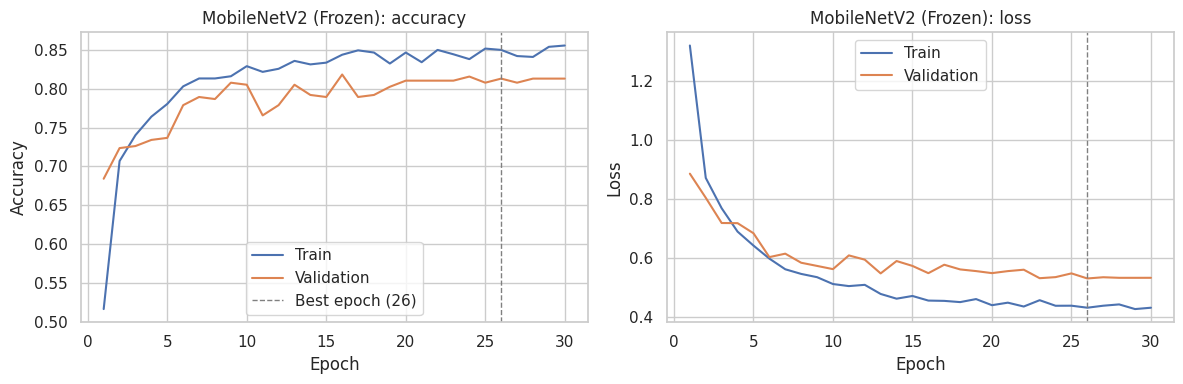

Final-epoch train acc 85.6% vs validation acc 81.3% (gap +4.3 points).
Best validation loss 0.531 at epoch 26; final validation loss is +0.002 above it.
Diagnosis: no strong sign of over- or underfitting.

Classification report (test set):
              precision    recall  f1-score   support

   cardboard      0.902     0.917     0.909        60
       glass      0.965     0.724     0.827        76
       metal      0.725     0.951     0.823        61
       paper      0.910     0.798     0.850        89
     plastic      0.833     0.903     0.867        72
       trash      0.600     0.714     0.652        21

    accuracy                          0.842       379
   macro avg      0.823     0.834     0.821       379
weighted avg      0.858     0.842     0.843       379



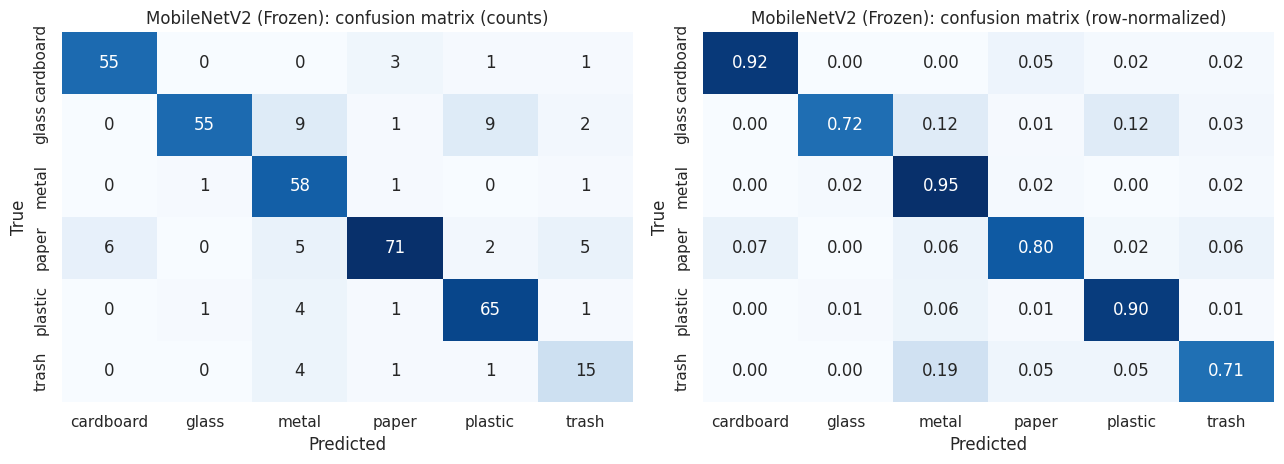

Test accuracy 84.17% | macro-F1 0.821
Training time: 2.4 min (143 s for 30 epochs) | Testing time: 3.10 s for 379 images (8.2 ms/image)
Parameters: 7,686 trainable of 2,231,558


In [8]:
ALL_METRICS["mobilenet_v2_frozen"] = run_experiment("mobilenet_v2", "frozen")

### 3.2 MobileNetV2: fine-tuned

[mobilenet_v2 | finetuned] epoch 01/30  train loss 1.074 acc 0.606  |  val loss 0.640 acc 0.761  (6.1s)
[mobilenet_v2 | finetuned] epoch 02/30  train loss 0.550 acc 0.803  |  val loss 0.532 acc 0.784  (4.4s)
[mobilenet_v2 | finetuned] epoch 03/30  train loss 0.424 acc 0.846  |  val loss 0.548 acc 0.800  (4.5s)
[mobilenet_v2 | finetuned] epoch 04/30  train loss 0.262 acc 0.910  |  val loss 0.506 acc 0.805  (4.5s)
[mobilenet_v2 | finetuned] epoch 05/30  train loss 0.243 acc 0.913  |  val loss 0.501 acc 0.826  (4.5s)
[mobilenet_v2 | finetuned] epoch 06/30  train loss 0.209 acc 0.931  |  val loss 0.426 acc 0.855  (4.4s)
[mobilenet_v2 | finetuned] epoch 07/30  train loss 0.161 acc 0.942  |  val loss 0.470 acc 0.858  (4.6s)
[mobilenet_v2 | finetuned] epoch 08/30  train loss 0.135 acc 0.950  |  val loss 0.415 acc 0.874  (4.6s)
[mobilenet_v2 | finetuned] epoch 09/30  train loss 0.123 acc 0.953  |  val loss 0.441 acc 0.850  (4.5s)
[mobilenet_v2 | finetuned] epoch 10/30  train loss 0.144 acc 0.9

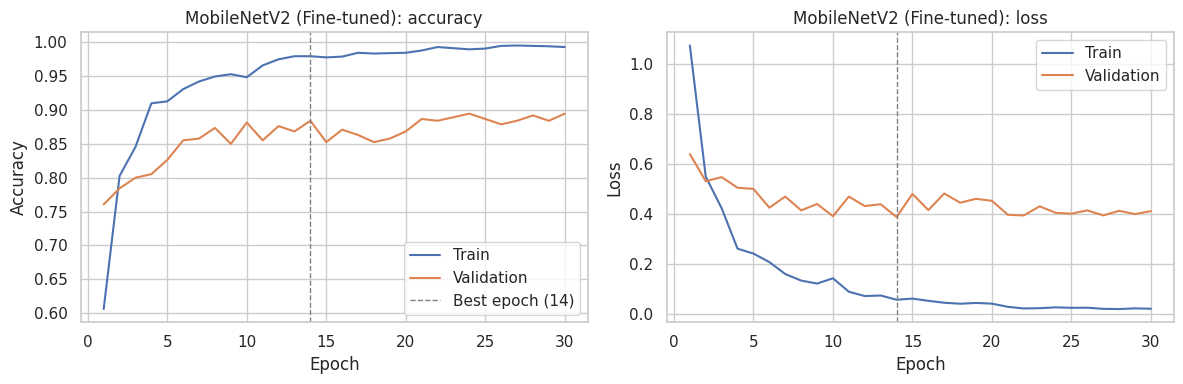

Final-epoch train acc 99.3% vs validation acc 89.5% (gap +9.8 points).
Best validation loss 0.389 at epoch 14; final validation loss is +0.023 above it.
Diagnosis: signs of OVERFITTING (large train-validation gap or rising validation loss). The best-validation-loss checkpoint is used for testing.

Classification report (test set):
              precision    recall  f1-score   support

   cardboard      0.965     0.917     0.940        60
       glass      0.953     0.803     0.871        76
       metal      0.889     0.918     0.903        61
       paper      0.898     0.888     0.893        89
     plastic      0.852     0.958     0.902        72
       trash      0.731     0.905     0.809        21

    accuracy                          0.894       379
   macro avg      0.881     0.898     0.886       379
weighted avg      0.900     0.894     0.895       379



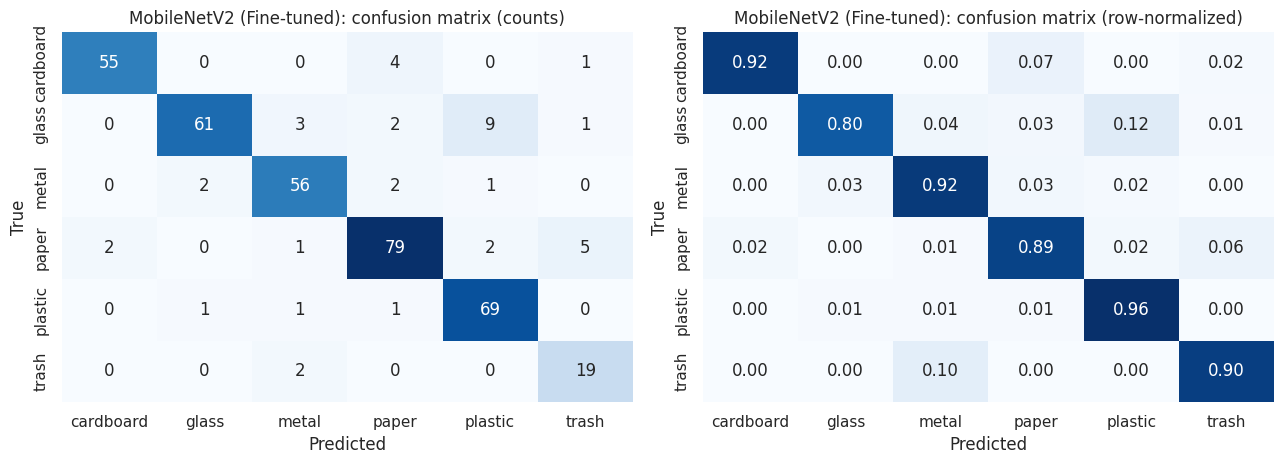

Test accuracy 89.45% | macro-F1 0.886
Training time: 2.3 min (137 s for 30 epochs) | Testing time: 0.55 s for 379 images (1.4 ms/image)
Parameters: 1,689,030 trainable of 2,231,558


In [9]:
ALL_METRICS["mobilenet_v2_finetuned"] = run_experiment("mobilenet_v2", "finetuned")

### 3.3 ResNet50: frozen

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 178MB/s]


[resnet50 | frozen] epoch 01/30  train loss 1.281 acc 0.522  |  val loss 0.806 acc 0.737  (4.9s)
[resnet50 | frozen] epoch 02/30  train loss 0.813 acc 0.723  |  val loss 0.698 acc 0.782  (4.5s)
[resnet50 | frozen] epoch 03/30  train loss 0.689 acc 0.762  |  val loss 0.713 acc 0.745  (4.6s)
[resnet50 | frozen] epoch 04/30  train loss 0.644 acc 0.778  |  val loss 0.649 acc 0.795  (4.7s)
[resnet50 | frozen] epoch 05/30  train loss 0.612 acc 0.784  |  val loss 0.617 acc 0.808  (4.7s)
[resnet50 | frozen] epoch 06/30  train loss 0.566 acc 0.807  |  val loss 0.683 acc 0.763  (4.6s)
[resnet50 | frozen] epoch 07/30  train loss 0.559 acc 0.801  |  val loss 0.616 acc 0.808  (4.6s)
[resnet50 | frozen] epoch 08/30  train loss 0.517 acc 0.827  |  val loss 0.623 acc 0.813  (4.7s)
[resnet50 | frozen] epoch 09/30  train loss 0.525 acc 0.818  |  val loss 0.624 acc 0.808  (4.5s)
[resnet50 | frozen] epoch 10/30  train loss 0.521 acc 0.820  |  val loss 0.564 acc 0.816  (4.6s)
[resnet50 | frozen] epoch 11/3

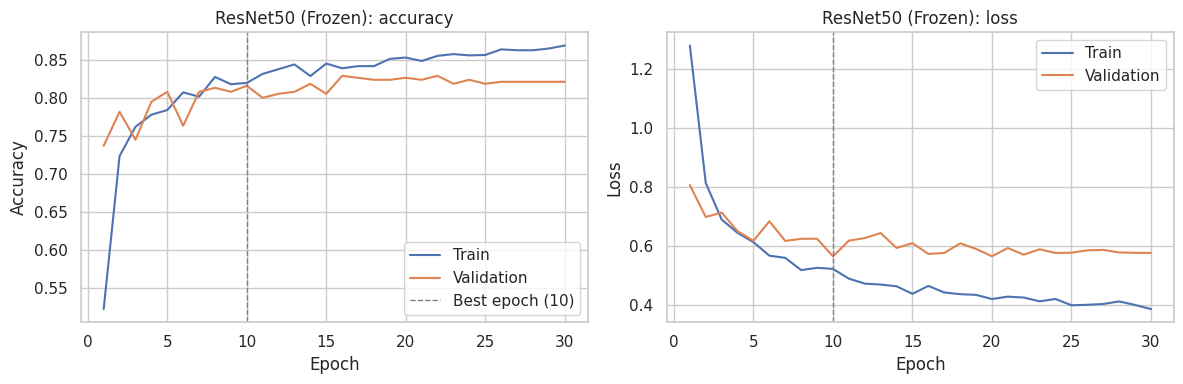

Final-epoch train acc 86.9% vs validation acc 82.1% (gap +4.8 points).
Best validation loss 0.564 at epoch 10; final validation loss is +0.012 above it.
Diagnosis: no strong sign of over- or underfitting.

Classification report (test set):
              precision    recall  f1-score   support

   cardboard      0.917     0.917     0.917        60
       glass      0.946     0.697     0.803        76
       metal      0.734     0.951     0.829        61
       paper      0.959     0.798     0.871        89
     plastic      0.722     0.903     0.802        72
       trash      0.700     0.667     0.683        21

    accuracy                          0.834       379
   macro avg      0.830     0.822     0.817       379
weighted avg      0.854     0.834     0.834       379



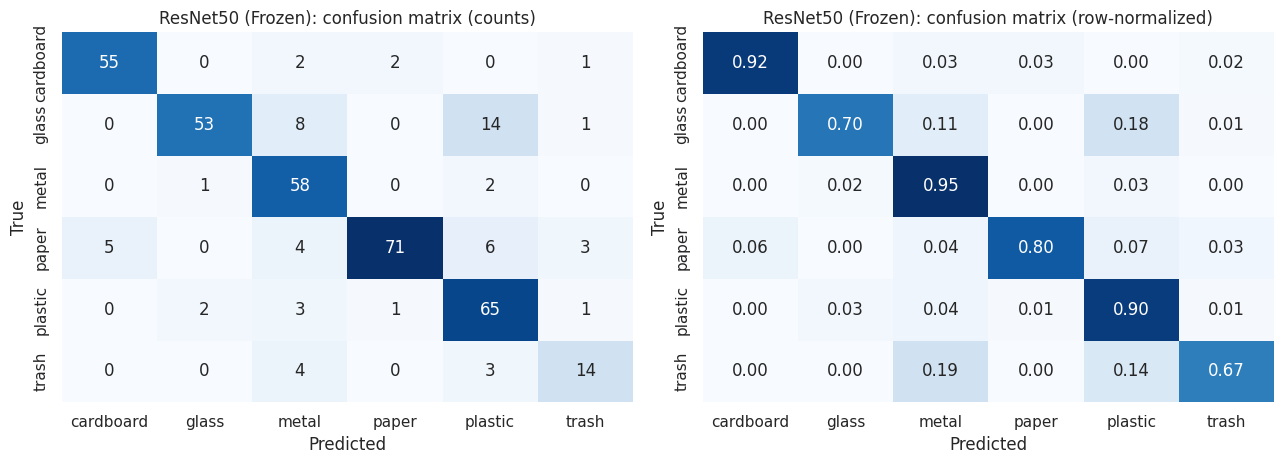

Test accuracy 83.38% | macro-F1 0.817
Training time: 2.3 min (138 s for 30 epochs) | Testing time: 0.77 s for 379 images (2.0 ms/image)
Parameters: 12,294 trainable of 23,520,326


In [10]:
ALL_METRICS["resnet50_frozen"] = run_experiment("resnet50", "frozen")

### 3.4 ResNet50: fine-tuned

[resnet50 | finetuned] epoch 01/30  train loss 0.901 acc 0.682  |  val loss 0.541 acc 0.797  (4.9s)
[resnet50 | finetuned] epoch 02/30  train loss 0.323 acc 0.891  |  val loss 0.390 acc 0.863  (4.6s)
[resnet50 | finetuned] epoch 03/30  train loss 0.262 acc 0.915  |  val loss 0.385 acc 0.884  (4.7s)
[resnet50 | finetuned] epoch 04/30  train loss 0.180 acc 0.938  |  val loss 0.624 acc 0.842  (4.8s)
[resnet50 | finetuned] epoch 05/30  train loss 0.163 acc 0.944  |  val loss 0.323 acc 0.897  (4.8s)
[resnet50 | finetuned] epoch 06/30  train loss 0.091 acc 0.969  |  val loss 0.282 acc 0.908  (4.7s)
[resnet50 | finetuned] epoch 07/30  train loss 0.094 acc 0.968  |  val loss 0.380 acc 0.889  (4.8s)
[resnet50 | finetuned] epoch 08/30  train loss 0.084 acc 0.977  |  val loss 0.501 acc 0.853  (4.7s)
[resnet50 | finetuned] epoch 09/30  train loss 0.099 acc 0.972  |  val loss 0.372 acc 0.900  (4.7s)
[resnet50 | finetuned] epoch 10/30  train loss 0.060 acc 0.973  |  val loss 0.298 acc 0.908  (4.7s)


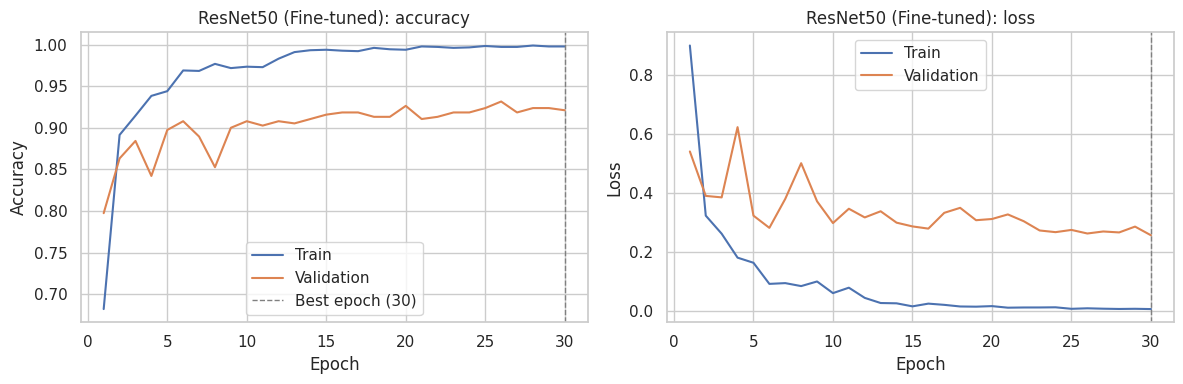

Final-epoch train acc 99.8% vs validation acc 92.1% (gap +7.7 points).
Best validation loss 0.256 at epoch 30; final validation loss is +0.000 above it.
Diagnosis: no strong sign of over- or underfitting.

Classification report (test set):
              precision    recall  f1-score   support

   cardboard      1.000     0.933     0.966        60
       glass      0.946     0.921     0.933        76
       metal      0.905     0.934     0.919        61
       paper      0.935     0.966     0.950        89
     plastic      0.919     0.944     0.932        72
       trash      0.950     0.905     0.927        21

    accuracy                          0.939       379
   macro avg      0.942     0.934     0.938       379
weighted avg      0.940     0.939     0.939       379



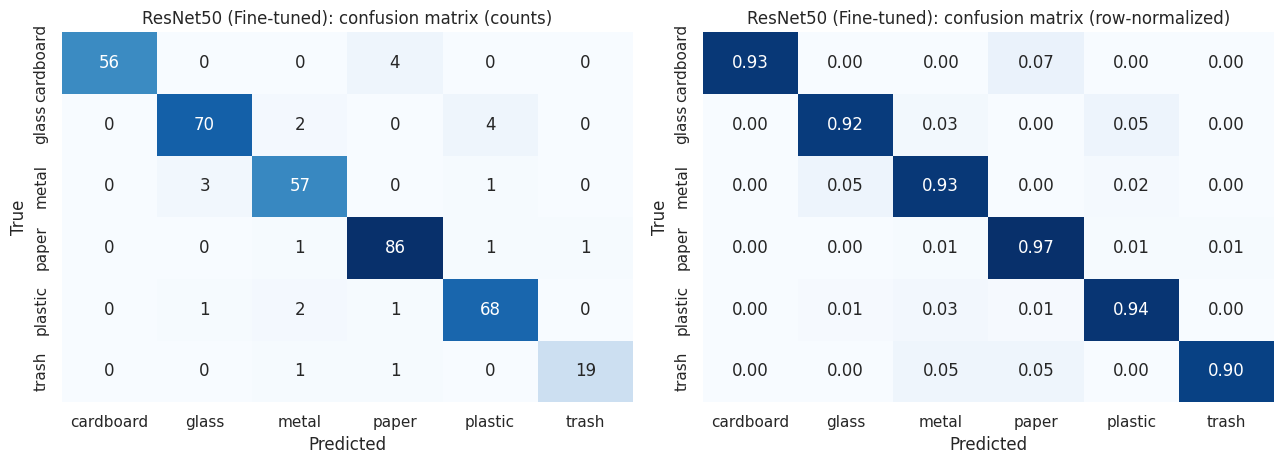

Test accuracy 93.93% | macro-F1 0.938
Training time: 2.4 min (143 s for 30 epochs) | Testing time: 0.72 s for 379 images (1.9 ms/image)
Parameters: 14,977,030 trainable of 23,520,326


In [11]:
ALL_METRICS["resnet50_finetuned"] = run_experiment("resnet50", "finetuned")

### 3.5 EfficientNetB0: frozen

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 133MB/s] 


[efficientnet_b0 | frozen] epoch 01/30  train loss 1.176 acc 0.615  |  val loss 0.752 acc 0.761  (11.8s)
[efficientnet_b0 | frozen] epoch 02/30  train loss 0.724 acc 0.776  |  val loss 0.591 acc 0.811  (4.3s)
[efficientnet_b0 | frozen] epoch 03/30  train loss 0.604 acc 0.811  |  val loss 0.526 acc 0.832  (4.3s)
[efficientnet_b0 | frozen] epoch 04/30  train loss 0.553 acc 0.829  |  val loss 0.496 acc 0.837  (4.1s)
[efficientnet_b0 | frozen] epoch 05/30  train loss 0.480 acc 0.846  |  val loss 0.470 acc 0.853  (4.1s)
[efficientnet_b0 | frozen] epoch 06/30  train loss 0.446 acc 0.856  |  val loss 0.451 acc 0.850  (4.3s)
[efficientnet_b0 | frozen] epoch 07/30  train loss 0.432 acc 0.857  |  val loss 0.450 acc 0.845  (4.3s)
[efficientnet_b0 | frozen] epoch 08/30  train loss 0.395 acc 0.867  |  val loss 0.431 acc 0.845  (4.2s)
[efficientnet_b0 | frozen] epoch 09/30  train loss 0.389 acc 0.876  |  val loss 0.427 acc 0.853  (4.3s)
[efficientnet_b0 | frozen] epoch 10/30  train loss 0.363 acc 0.

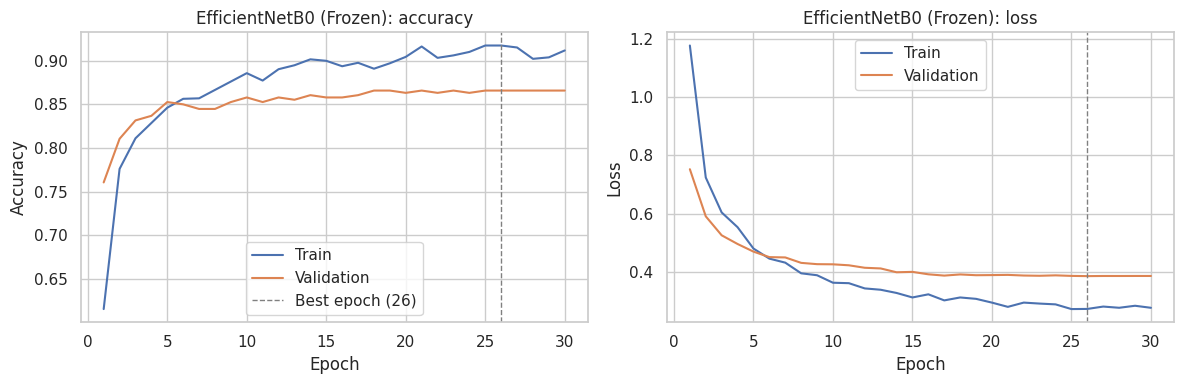

Final-epoch train acc 91.2% vs validation acc 86.6% (gap +4.6 points).
Best validation loss 0.386 at epoch 26; final validation loss is +0.001 above it.
Diagnosis: no strong sign of over- or underfitting.

Classification report (test set):
              precision    recall  f1-score   support

   cardboard      0.966     0.933     0.949        60
       glass      0.931     0.882     0.905        76
       metal      0.855     0.967     0.908        61
       paper      0.964     0.910     0.936        89
     plastic      0.870     0.931     0.899        72
       trash      0.895     0.810     0.850        21

    accuracy                          0.916       379
   macro avg      0.913     0.905     0.908       379
weighted avg      0.918     0.916     0.916       379



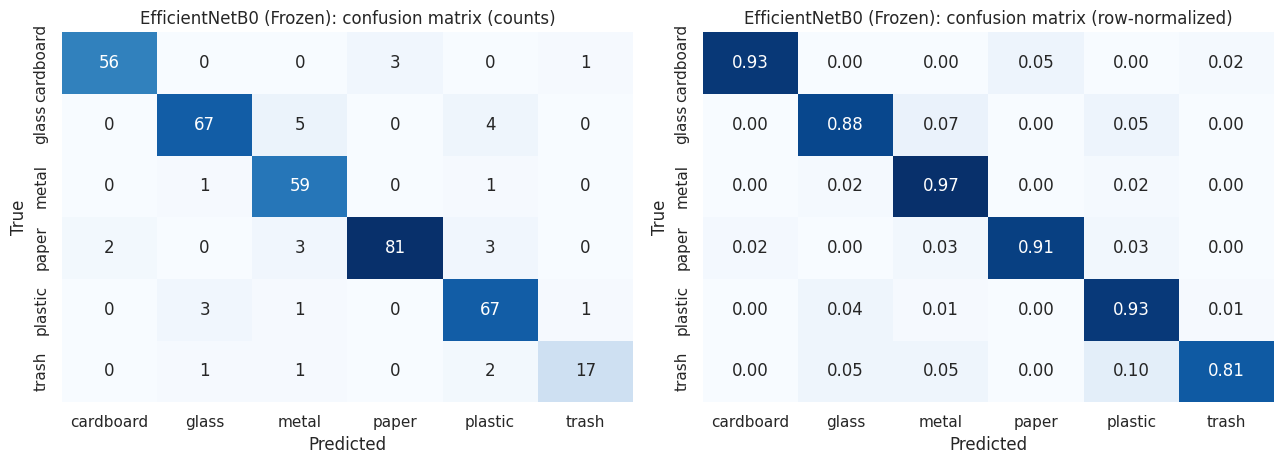

Test accuracy 91.56% | macro-F1 0.908
Training time: 2.2 min (135 s for 30 epochs) | Testing time: 3.14 s for 379 images (8.3 ms/image)
Parameters: 7,686 trainable of 4,015,234


In [12]:
ALL_METRICS["efficientnet_b0_frozen"] = run_experiment("efficientnet_b0", "frozen")

### 3.6 EfficientNetB0: fine-tuned

[efficientnet_b0 | finetuned] epoch 01/30  train loss 1.187 acc 0.626  |  val loss 0.652 acc 0.787  (6.8s)
[efficientnet_b0 | finetuned] epoch 02/30  train loss 0.572 acc 0.808  |  val loss 0.449 acc 0.839  (4.4s)
[efficientnet_b0 | finetuned] epoch 03/30  train loss 0.354 acc 0.896  |  val loss 0.373 acc 0.887  (4.5s)
[efficientnet_b0 | finetuned] epoch 04/30  train loss 0.272 acc 0.906  |  val loss 0.337 acc 0.895  (4.5s)
[efficientnet_b0 | finetuned] epoch 05/30  train loss 0.179 acc 0.941  |  val loss 0.299 acc 0.895  (4.4s)
[efficientnet_b0 | finetuned] epoch 06/30  train loss 0.148 acc 0.952  |  val loss 0.303 acc 0.895  (4.5s)
[efficientnet_b0 | finetuned] epoch 07/30  train loss 0.116 acc 0.962  |  val loss 0.286 acc 0.897  (4.4s)
[efficientnet_b0 | finetuned] epoch 08/30  train loss 0.094 acc 0.967  |  val loss 0.289 acc 0.916  (4.4s)
[efficientnet_b0 | finetuned] epoch 09/30  train loss 0.071 acc 0.977  |  val loss 0.258 acc 0.916  (4.5s)
[efficientnet_b0 | finetuned] epoch 1

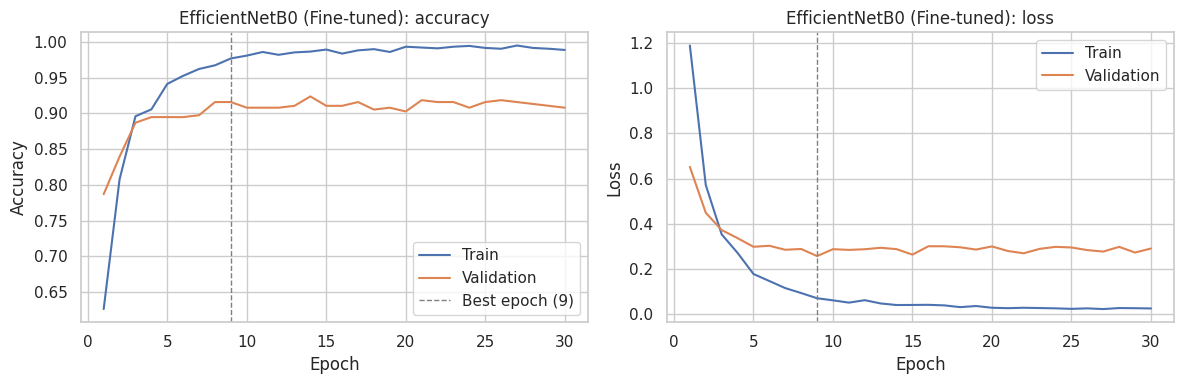

Final-epoch train acc 98.9% vs validation acc 90.8% (gap +8.1 points).
Best validation loss 0.258 at epoch 9; final validation loss is +0.033 above it.
Diagnosis: signs of OVERFITTING (large train-validation gap or rising validation loss). The best-validation-loss checkpoint is used for testing.

Classification report (test set):
              precision    recall  f1-score   support

   cardboard      0.934     0.950     0.942        60
       glass      0.969     0.829     0.894        76
       metal      0.879     0.951     0.913        61
       paper      0.953     0.921     0.937        89
     plastic      0.872     0.944     0.907        72
       trash      0.870     0.952     0.909        21

    accuracy                          0.918       379
   macro avg      0.913     0.925     0.917       379
weighted avg      0.921     0.918     0.918       379



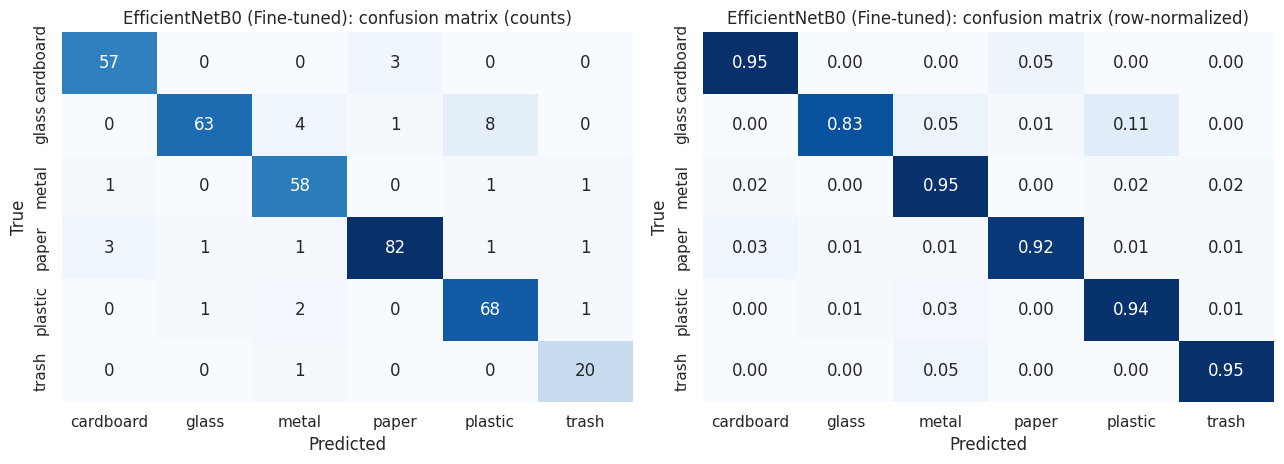

Test accuracy 91.82% | macro-F1 0.917
Training time: 2.3 min (136 s for 30 epochs) | Testing time: 0.57 s for 379 images (1.5 ms/image)
Parameters: 3,163,426 trainable of 4,015,234


In [13]:
ALL_METRICS["efficientnet_b0_finetuned"] = run_experiment("efficientnet_b0", "finetuned")

## 4. Comparison of all six runs

All numbers below are measured on the **same held-out test set** with the same preprocessing and epoch budget. Training time includes validation after every epoch; testing time is one pass over the test set including data loading.

,model,mode,test acc (%),macro P,macro R,macro F1,weighted F1,train acc (%),val acc (%),best epoch,train time (s),test time (s),trainable params
0,MobileNetV2,Frozen,84.17,0.823,0.834,0.821,0.843,85.58,81.32,26,143,3.10,7686
1,MobileNetV2,Fine-tuned,89.45,0.881,0.898,0.886,0.895,99.32,89.47,14,137,0.55,1689030
2,ResNet50,Frozen,83.38,0.830,0.822,0.817,0.834,86.88,82.11,10,138,0.77,12294
3,ResNet50,Fine-tuned,93.93,0.942,0.934,0.938,0.939,99.77,92.11,30,143,0.72,14977030
4,EfficientNetB0,Frozen,91.56,0.913,0.905,0.908,0.916,91.18,86.58,26,135,3.14,7686
5,EfficientNetB0,Fine-tuned,91.82,0.913,0.925,0.917,0.918,98.87,90.79,9,136,0.57,3163426


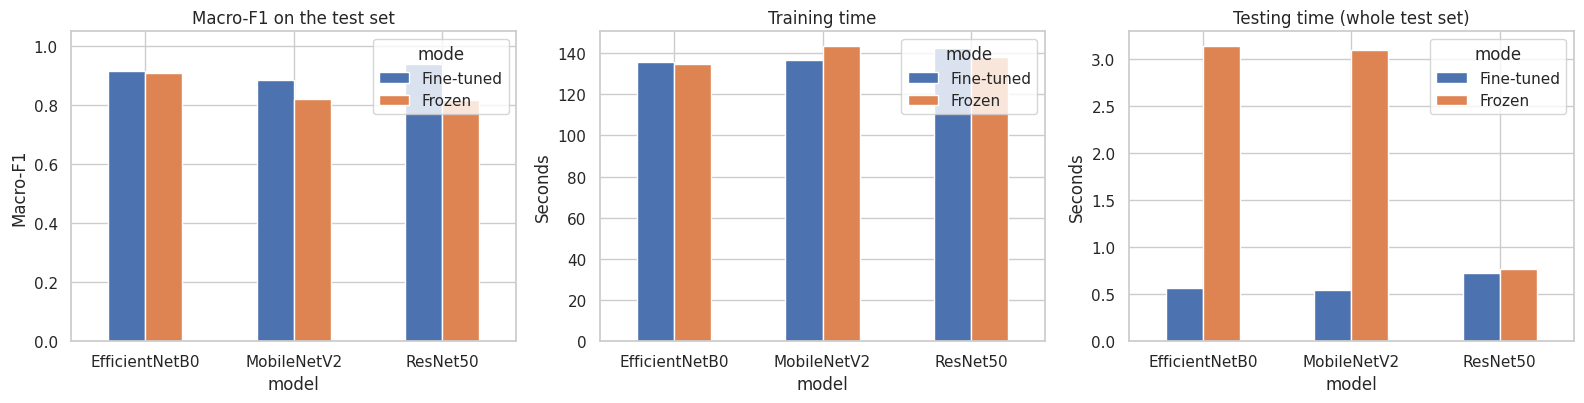

In [14]:
summary = pd.DataFrame(ALL_METRICS.values())
cols = ["model", "mode", "test_acc", "macro_precision", "macro_recall", "macro_f1", "weighted_f1",
        "final_train_acc", "final_val_acc", "best_epoch", "train_time_s", "test_time_s", "trainable_params"]
summary = summary[cols].copy()
summary.to_csv(RESULTS / "summary_all_runs.csv", index=False)

show = summary.copy()
for c in ["test_acc", "final_train_acc", "final_val_acc"]:
    show[c] = (show[c] * 100).round(2)
for c in ["macro_precision", "macro_recall", "macro_f1", "weighted_f1"]:
    show[c] = show[c].round(3)
show["train_time_s"] = show["train_time_s"].round(0).astype(int)
show["test_time_s"] = show["test_time_s"].round(2)
show = show.rename(columns={"test_acc": "test acc (%)", "macro_precision": "macro P", "macro_recall": "macro R",
                            "macro_f1": "macro F1", "weighted_f1": "weighted F1", "final_train_acc": "train acc (%)",
                            "final_val_acc": "val acc (%)", "best_epoch": "best epoch",
                            "train_time_s": "train time (s)", "test_time_s": "test time (s)", "trainable_params": "trainable params"})
display(show)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
piv = lambda col: summary.pivot(index="model", columns="mode", values=col)
piv("macro_f1").plot(kind="bar", ax=ax[0], rot=0); ax[0].set_title("Macro-F1 on the test set"); ax[0].set_ylabel("Macro-F1"); ax[0].set_ylim(0, 1.05)
piv("train_time_s").plot(kind="bar", ax=ax[1], rot=0); ax[1].set_title("Training time"); ax[1].set_ylabel("Seconds")
piv("test_time_s").plot(kind="bar", ax=ax[2], rot=0); ax[2].set_title("Testing time (whole test set)"); ax[2].set_ylabel("Seconds")
plt.tight_layout(); plt.savefig(FIGS / "comparison.png", dpi=200); plt.show()

,cardboard,glass,metal,paper,plastic,trash
MobileNetV2 (Frozen),0.909,0.827,0.823,0.850,0.867,0.652
MobileNetV2 (Fine-tuned),0.940,0.871,0.903,0.893,0.902,0.809
ResNet50 (Frozen),0.917,0.803,0.829,0.871,0.802,0.683
ResNet50 (Fine-tuned),0.966,0.933,0.919,0.950,0.932,0.927
EfficientNetB0 (Frozen),0.949,0.905,0.908,0.936,0.899,0.850
EfficientNetB0 (Fine-tuned),0.942,0.894,0.913,0.937,0.907,0.909


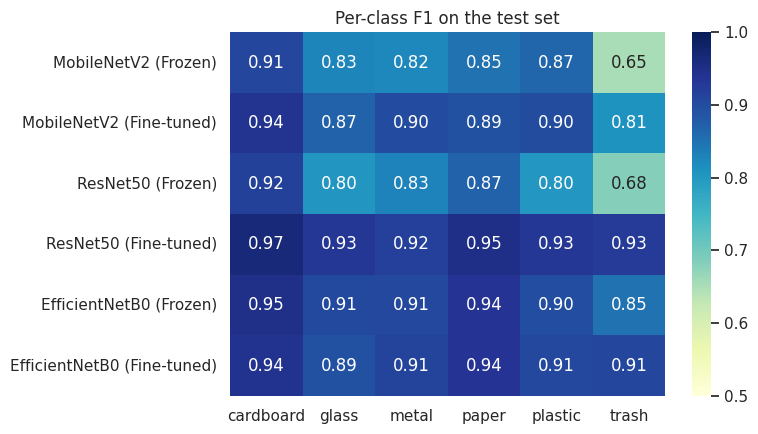

In [15]:
# Per-class F1 of every run, to see which classes are hardest
rows = {}
for run, met in ALL_METRICS.items():
    p = np.load(RESULTS / run / "preds.npz")
    _, _, f1c, _ = precision_recall_fscore_support(p["y_true"], p["y_pred"], labels=range(len(CLASSES)), zero_division=0)
    rows[f"{met['model']} ({met['mode']})"] = f1c
per_class = pd.DataFrame(rows, index=CLASSES).T.round(3)
display(per_class)
plt.figure(figsize=(8, 4.5)); sns.heatmap(per_class, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0.5, vmax=1)
plt.title("Per-class F1 on the test set"); plt.tight_layout(); plt.savefig(FIGS / "per_class_f1.png", dpi=200); plt.show()

## 5. Discussion

All six runs used the same split, preprocessing, optimizer settings and 30-epoch budget. The test set was used once per run, after the best-validation-loss checkpoint was restored, and no hyperparameters were changed after seeing test results.

### 5.1 Frozen versus fine-tuned

| Model | Frozen (accuracy / macro-F1) | Fine-tuned (accuracy / macro-F1) | Change in accuracy |
|---|---|---|---|
| MobileNetV2 | 84.17% / 0.821 | 89.45% / 0.886 | +5.28 points |
| ResNet50 | 83.38% / 0.817 | 93.93% / 0.938 | +10.55 points |
| EfficientNetB0 | 91.56% / 0.908 | 91.82% / 0.917 | +0.26 points |

Fine-tuning helped most for ResNet50 (40 more correctly classified test images) and MobileNetV2 (20 more). For EfficientNetB0 the difference is a single image (348 versus 347 correct), which is no evidence of a real improvement; its frozen ImageNet features already gave 91.56% with only 7,686 trainable parameters. The two weaker frozen models trained only a small head (7,686 and 12,294 parameters) and levelled off at about 86-87% training accuracy, which suggests that the frozen features limited them. Fine-tuning cost almost no extra training time here (135-143 s for every run).

### 5.2 Best model

ResNet50 fine-tuned is the best run (93.93% accuracy, macro-F1 0.938) and has the highest F1 in every class. The next best is EfficientNetB0 fine-tuned (91.82%, 0.917), eight images fewer correct. A difference of about 2 points is comparable to the sampling uncertainty of a 379-image test set (roughly plus or minus 2.4 points at 95% for accuracy near 94%), and only one split and one seed were run, so the order of the top runs should not be treated as certain. The difference between the three runs above 91% (ResNet50 fine-tuned and both EfficientNetB0 runs) and the others (83-89%) is clearer.

### 5.3 Overfitting and underfitting

The three frozen runs show a train-validation accuracy gap of 4.3-4.8 points and no sign of overfitting. The three fine-tuned runs reach 98.9-99.8% training accuracy against 89.5-92.1% validation accuracy, a gap of 9.8 points for MobileNetV2, 7.7 for ResNet50 and 8.1 for EfficientNetB0 (training accuracy is measured while augmentation and dropout are active). The automatic diagnostic flagged MobileNetV2 and EfficientNetB0 as overfitting; ResNet50 fell just under the 8-point threshold, and its validation loss kept improving until epoch 30.

The measures used against overfitting were data augmentation, dropout (0.3), weight decay, a cosine learning-rate schedule, a smaller learning rate for the unfrozen backbone, class-weighted loss and restoring the best-validation-loss checkpoint. The last one mattered: for MobileNetV2 and EfficientNetB0 the best validation loss occurred at epochs 14 and 9 (0.389 and 0.258), so the model tested was not the final, more overfitted epoch. A gap of about 8-10 points still remains, which is expected when 1.7-15 million parameters are trained on 1,768 images. Stronger regularization or unfreezing fewer layers could reduce it but would change the settings between runs.

### 5.4 Errors by class

Trash had the lowest F1 in four of the six runs (frozen MobileNetV2 0.652, frozen ResNet50 0.683, frozen EfficientNetB0 0.850 and fine-tuned MobileNetV2 0.809), which fits it being the smallest class (137 images) and a mixed category, as found in Submission 1. The fine-tuned ResNet50 and EfficientNetB0 raised trash to 0.927 and 0.909. Trash has only 21 test images, so a single error changes its recall by about 4.8 points and its scores are noisy.

In the frozen MobileNetV2 and ResNet50 models, glass was the class most often confused. Of the 76 glass test images, MobileNetV2 predicted 9 as metal and 9 as plastic, and ResNet50 predicted 8 as metal and 14 as plastic (glass recall 0.724 and 0.697). Both models also predicted 4 of the 21 trash images as metal. These errors fit the shiny, transparent or reflective surfaces of glass, plastic and metal noted in Submission 1.

### 5.5 Efficiency

ResNet50 has 23.5M parameters, about 5.9 times EfficientNetB0 (4.0M) and 10.5 times MobileNetV2 (2.2M), and it trains 15.0M of them when fine-tuned. EfficientNetB0 gave the best accuracy for its size: 91.56% frozen with only 7,686 trained parameters. MobileNetV2 fine-tuned is the smallest model and still reached 89.45%. Training time was almost identical in all runs (about 4.2-4.8 s per epoch), which likely means the training loop was limited by image loading and augmentation rather than by the GPU, so it does not reflect model cost here. Testing time for the fine-tuned runs was 0.55-0.72 s for 379 images (1.4-1.9 ms per image). The frozen MobileNetV2 and EfficientNetB0 runs took about 3.1 s even though inference is identical to their fine-tuned versions; this is most likely GPU warm-up on first use and not a real difference.

### 5.6 Limitations

Results come from one split and one seed. The 379 test images mean one image equals 0.26 percentage points. TrashNet has a plain white background and a few duplicate images with conflicting labels (Submission 1), so results may not carry over to cluttered real-world photographs. Hyperparameters were fixed in advance and not tuned per model, and the timing measurements include the warm-up effect noted above. These scores are not directly comparable with those of the papers in Submission 1, which used different splits and protocols.

## 6. Conclusion and link to the next submissions

The best configuration was ResNet50 fine-tuned, with 93.93% test accuracy and macro-F1 0.938, followed by EfficientNetB0 fine-tuned at 91.82%. Fine-tuning gave large gains for ResNet50 (+10.55 points) and MobileNetV2 (+5.28 points) but almost none for EfficientNetB0, whose frozen features were already strong. The main remaining weaknesses are the 8-10 point train-validation gap in the fine-tuned models and the lower, noisier scores on the small trash class. These six runs serve as the pretrained-model reference for the custom CNN trained from scratch (Submission 3) and the custom CNN with an attention module (Submission 4), which will use the same split and metrics.

## References

1. G. Thung and M. Yang, "TrashNet: Dataset of images of trash," GitHub repository, https://github.com/garythung/trashnet
2. M. Sandler, A. Howard, M. Zhu, A. Zhmoginov and L.-C. Chen, "MobileNetV2: Inverted Residuals and Linear Bottlenecks," CVPR, 2018.
3. K. He, X. Zhang, S. Ren and J. Sun, "Deep Residual Learning for Image Recognition," CVPR, 2016.
4. M. Tan and Q. V. Le, "EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks," ICML, 2019.
5. A. Paszke et al., "PyTorch: An Imperative Style, High-Performance Deep Learning Library," NeurIPS, 2019.